# Comparing FN-DMC results from several packages

In [3]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from io import StringIO

import pyblock
from scipy.optimize import curve_fit

from myfit import *
from myfunctions import *
from mysetup import *

In [4]:
import pickle

with open('results_data.pkl','rb') as fp:
    data = pickle.load(fp)
    print('Dictionary data with all results read in results_data.pkl')
    
data['CASINO'] = data['CASINO_limdmc5']

Dictionary data with all results read in results_data.pkl


In [10]:
data

{'TurboRVB': {'m_LA': None,
  'w_LA': None,
  'mw_LA': None,
  'm---w_LA': None,
  'm_TM':            ene       err       x
  a                               
  0.05 -8.080926  0.000064  0.0025
  0.10 -8.081144  0.000060  0.0100
  0.15 -8.081231  0.000063  0.0225
  0.20 -8.081511  0.000064  0.0400
  0.25 -8.081657  0.000065  0.0625
  0.30 -8.081877  0.000063  0.0900,
  'w_TM':             ene       err       x
  a                                
  0.05 -17.239627  0.000051  0.0025
  0.10 -17.239859  0.000050  0.0100
  0.15 -17.239984  0.000052  0.0225
  0.20 -17.240263  0.000050  0.0400
  0.25 -17.240604  0.000050  0.0625
  0.30 -17.241017  0.000052  0.0900,
  'mw_TM':             ene       err       x
  a                                
  0.05 -25.321603  0.000037  0.0025
  0.10 -25.321946  0.000037  0.0100
  0.15 -25.322342  0.000039  0.0225
  0.20 -25.322832  0.000038  0.0400
  0.25 -25.323417  0.000037  0.0625
  0.30 -25.324006  0.000040  0.0900,
  'm---w_TM':             ene      

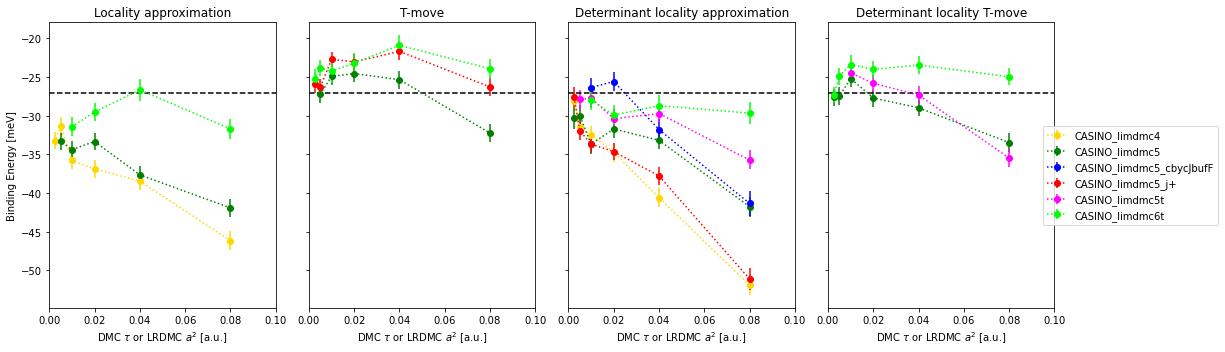

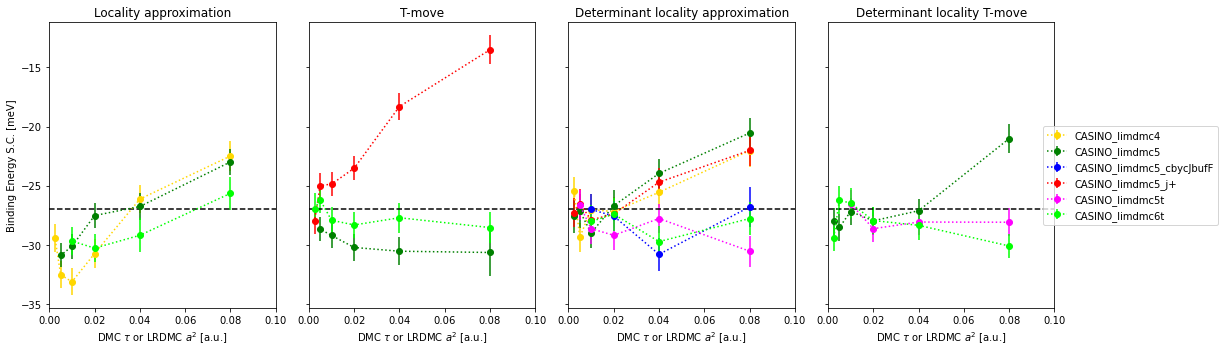

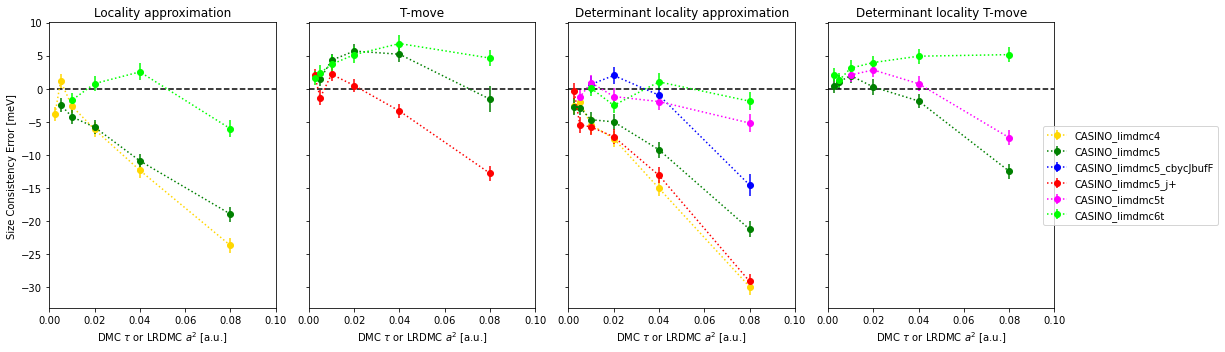

In [5]:
for ed in Ediffs:
    fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )
    ax[0].set_ylabel( Ediffs_label[ed] )

    for i, method in enumerate(methods):
        ax[i].set_xlim(0,taumax)
        ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
        for code in codes_casino:
            #print(code)
            try:
                #print(data[code][f'SCE_{method}'])
                datac1 = data[code][f'{ed}_{method}']
                datac1['x'] = x_axis( datac1, code )
                datac = datac1[ datac1.x <= taumax ]
                x = datac.x
                y = datac.ene
                y_err = datac.err
                ax[i].errorbar( x, y, y_err, fmt='o:', 
                               label=code, color=colors_all[code] )
            except:
                pass
        ax[i].axhline(y=Ediffs_ref[ed],color='black',ls='--')

    ax[0].set_title('Locality approximation')
    ax[1].set_title('T-move')
    ax[2].set_title('Determinant locality approximation')
    ax[3].set_title('Determinant locality T-move')

    leg = {}
    for i in range(4): 
        handles, labels = ax[i].get_legend_handles_labels()
        for j in range(len(labels)):
            leg[labels[j]] = handles[j]
    import collections
    leg = collections.OrderedDict(sorted(leg.items()))
    #aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
    legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


    plt.tight_layout()
    fig.savefig(f'Fig_{ed}_casino.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')

In [4]:
codes

['TurboRVB',
 'CASINO',
 'QMCPACK',
 'CHAMP_Holland',
 'CHAMP_Cornell_Paris',
 'QMC=Chem',
 'QMeCha',
 'PyQMC',
 'Amolqc',
 'QWalk',
 'CMQMC']

In [7]:
codes_sel3 = [ 'CASINO', 'QMCPACK', 'TurboRVB', 'CHAMP_Cornell_Paris', 'QMeCha', 'CMQMC' ]

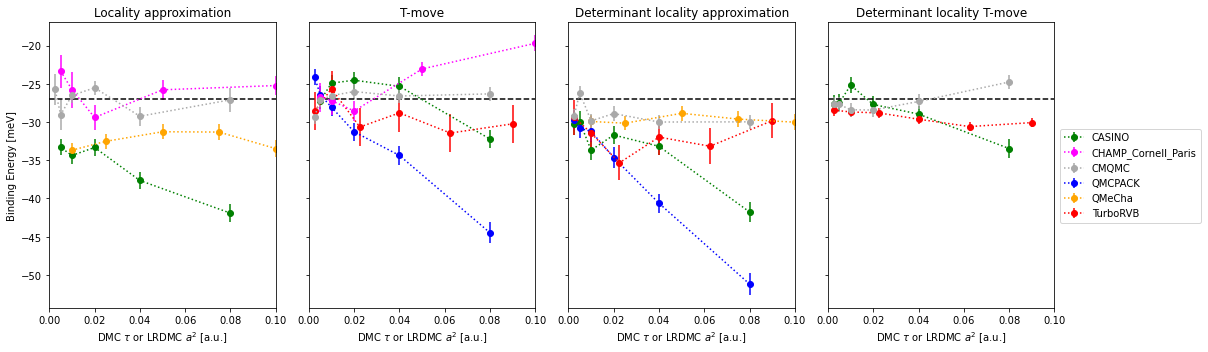

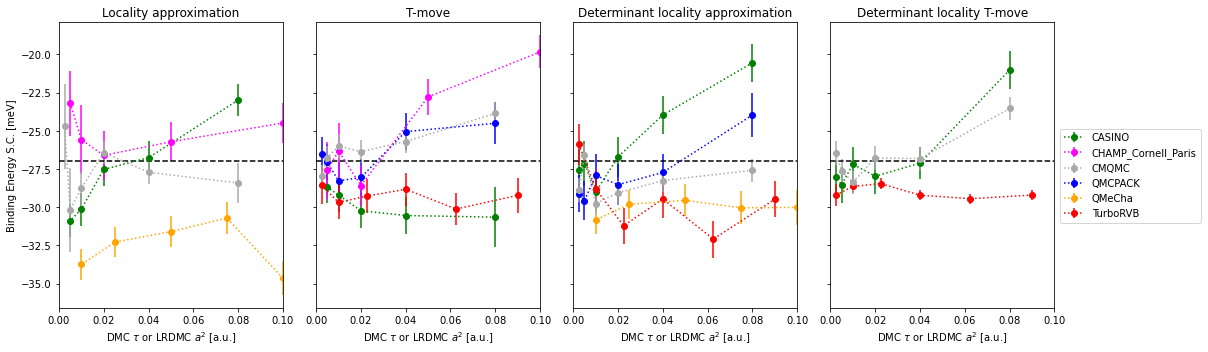

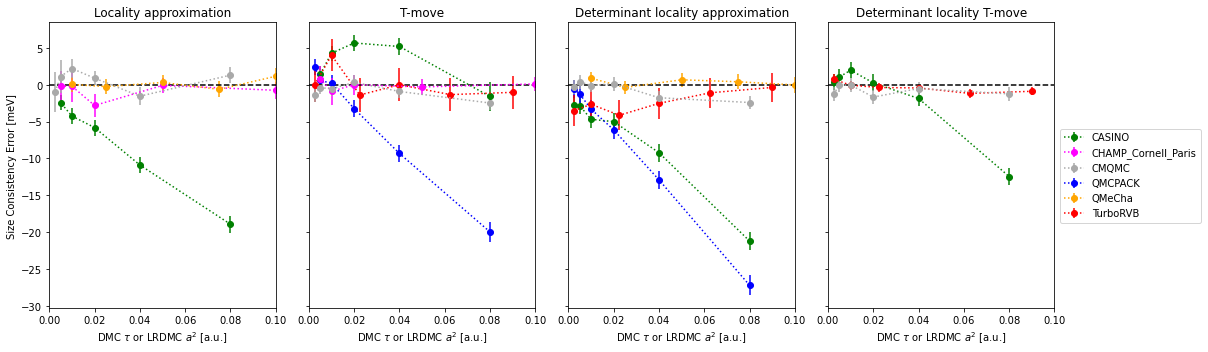

In [8]:
for ed in Ediffs:
    fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )
    ax[0].set_ylabel( Ediffs_label[ed] )

    for i, method in enumerate(methods):
        ax[i].set_xlim(0,taumax)
        ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
        for code in codes_sel3:
            #print(code)
            try:
                #print(data[code][f'SCE_{method}'])
                datac1 = data[code][f'{ed}_{method}']
                datac1['x'] = x_axis( datac1, code )
                datac = datac1[ datac1.x <= taumax ]
                x = datac.x
                y = datac.ene
                y_err = datac.err
                ax[i].errorbar( x, y, y_err, fmt='o:', 
                               label=code, color=colors_all[code] )
            except:
                pass
        ax[i].axhline(y=Ediffs_ref[ed],color='black',ls='--')

    ax[0].set_title('Locality approximation')
    ax[1].set_title('T-move')
    ax[2].set_title('Determinant locality approximation')
    ax[3].set_title('Determinant locality T-move')

    leg = {}
    for i in range(4): 
        handles, labels = ax[i].get_legend_handles_labels()
        for j in range(len(labels)):
            leg[labels[j]] = handles[j]
    import collections
    leg = collections.OrderedDict(sorted(leg.items()))
    #aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
    legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


    plt.tight_layout()
    fig.savefig(f'Fig_{ed}_sel.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')

# Fit and extrapolation

EXCEPTION >  QMCPACK LA Eb 'Eb_LA' 

EXCEPTION >  TurboRVB LA Eb 'Eb_LA' 

EXCEPTION >  QMCPACK DLTM Eb 'Eb_DLTM' 

EXCEPTION >  QMCPACK LA Ebsc 'Ebsc_LA' 

EXCEPTION >  TurboRVB LA Ebsc 'Ebsc_LA' 

EXCEPTION >  QMCPACK DLTM Ebsc 'Ebsc_DLTM' 

EXCEPTION >  QMCPACK LA SCE 'SCE_LA' 

EXCEPTION >  TurboRVB LA SCE 'SCE_LA' 

EXCEPTION >  QMCPACK DLTM SCE 'SCE_DLTM' 

       Q method      code        ene       err   err_fit      chi2  ndof  \
0     Eb     LA    CASINO -32.770973  1.181367  1.213694  2.280413     3   
1     Eb     TM    CASINO -27.222485  1.191295  0.949571  1.319821     3   
2     Eb     TM   QMCPACK -24.467716  0.853136  0.909558  2.937823     4   
3     Eb     TM  TurboRVB -26.993240  2.132726  1.763514  2.104339     4   
4     Eb    DLA    CASINO -31.207143  1.041956  1.350108  5.198920     4   
5     Eb    DLA   QMCPACK -28.903712  0.986031  0.343674  0.404917     4   
6     Eb    DLA  TurboRVB -29.842584  2.003450  1.619232  1.925777     4   
7     Eb   DLTM    CASINO 

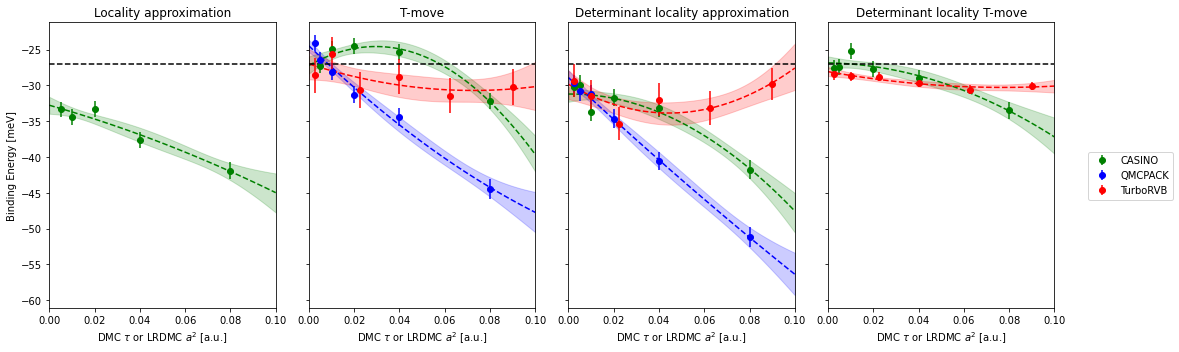

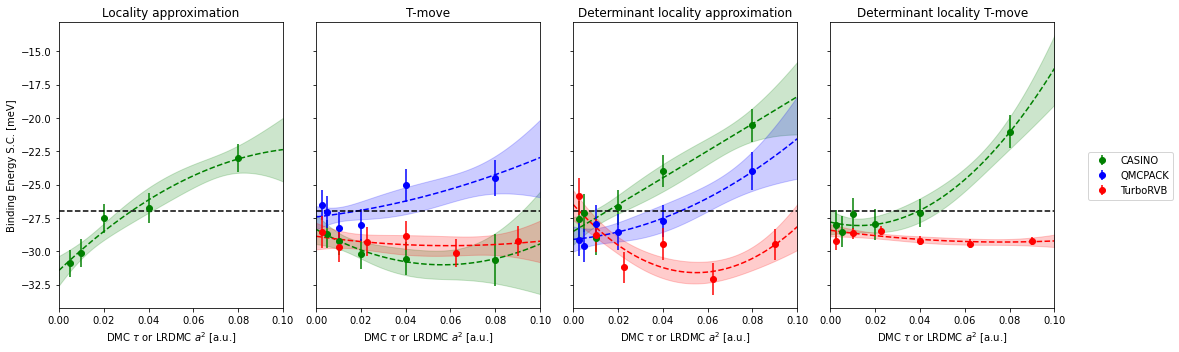

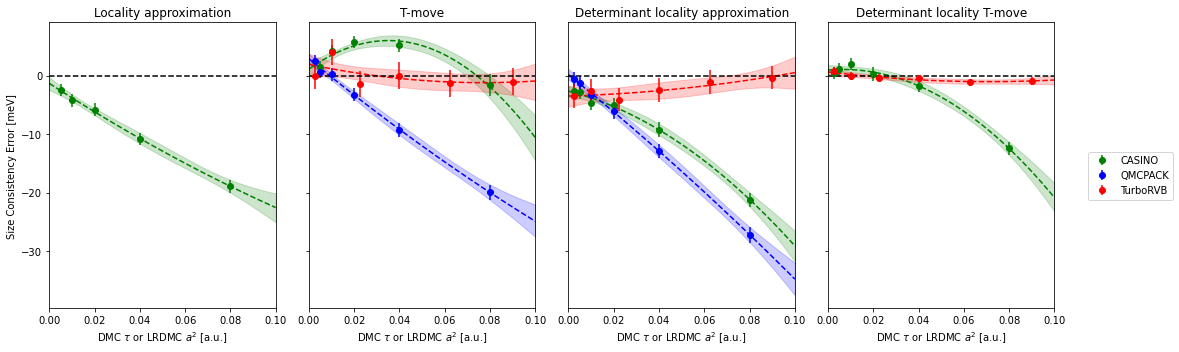

In [9]:
makefit = True
makefiterr = True
makefiterrOLS = False
verbose = False

# list with results
l = []

#for ed in ['Eb']:
for ed in Ediffs:
    fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )
    ax[0].set_ylabel( Ediffs_label[ed] )

    for i, method in enumerate(methods):
        ax[i].set_xlim(0,taumax)
        ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
        #for code in ['CASINO']:    # <=== selection
        for code in codes_sel:    # <=== selection
        #for code in codes_sel3:    # <=== selection
            #print(code)
            try:
                #print(data[code][f'SCE_{method}'])
                datac1 = data[code][f'{ed}_{method}']
                datac1['x'] = x_axis( datac1, code )
                datac = datac1[ datac1.x <= taumax ]
                datac = datac.dropna()
                x = datac.x
                y = datac.ene
                y_err = datac.err
                ax[i].errorbar( x, y, y_err, fmt='o', 
                               label=code, color=colors_all[code] )
                if makefit:
                    #print('Fit')
                    fun = fun_quad
                    xdata = x.to_numpy()
                    ydata = y.to_numpy()
                    sigma = y_err.to_numpy()
                    popt, pcov = curve_fit( fun, xdata=xdata, ydata=ydata, sigma=sigma )
                    chi2, ndof, alpha = get_chi2_alpha_fitfun( xdata, ydata, sigma, fun, popt )
                    xlinspace = np.linspace( 0, taumax, 100)
                    funlinspace = fun( xlinspace, *popt )
                    ax[i].plot( xlinspace, funlinspace, '--', color=colors_all[code] )
                    popterr = np.array([pcov[i,i] for i in range(len(pcov))])**0.5
                    if verbose:
                        print('FIT',code, method, ed)
                        print( f'popt = {popt}' )
                        print( f'perr = {popterr}' )
                        print( f'pcov = {pcov}' )
                        print( f'Eb = {popt[0]:6.2f} +/- {popterr[0]:4.2f}')
                        print( f'    chi2={chi2:5.3f}, df={ndof}, alpha={alpha:5.3f}' )
                    if makefiterrOLS:
                        if verbose:
                            print('FITERR OLS',code, method, ed)
                        # Y = a + b X + c X^2 + d X^3
                        # Var(Y) = Var(a) + Var(b) * X^2 + 2 * Cov(a,b) * X + ...
                        def fun_var_y( x, cov ):
                            s = 0.0
                            for i in range(len(cov)):
                                for j in range(len(cov)):
                                    s += cov[i,j] * x**(i+j) 
                            return s
                        popt, pcov = curve_fit( fun, xdata=xdata, ydata=ydata, sigma=sigma )
                        var_y = fun_var_y( xlinspace, pcov )
                        err_y = var_y**0.5
                        ax[i].plot(xlinspace,funlinspace+err_y,':',color=colors_all[code])
                        ax[i].plot(xlinspace,funlinspace-err_y,'-.',color=colors_all[code])
                    if makefiterr:
                        if verbose:
                            print('FITERR',code, method, ed)
                        xfit, m, s = fit_err(xdata,ydata,sigma,fitfun=fun,xmax=taumax)
                        #print('FITERR2',m,s)
                        #ax[i].plot(xfit,m,'--',color='k')
                        ax[i].fill_between(xfit,m-1*s,m+1*s,color=colors_all[code],alpha=0.2)
                        chi2, ndof, alpha = get_chi2_alpha_parfun( xdata, ydata, sigma, xfit, m, p=1 )
                        if verbose:
                            print(f'Eb = {m[0]:6.2f} +/- {s[0]:4.2f} <=== fiterror')
                            print( f'    chi2={chi2:5.3f}, df={ndof}, alpha={alpha:5.3f}' )
                            print()
                        # save results
                        res = {}
                        res['Q'] = ed
                        res['method'] = method
                        res['code'] = code
                        res['ene'] = popt[0]
                        res['err'] = s[0]
                        res['err_fit'] = popterr[0]
                        res['chi2'] = chi2
                        res['ndof'] = ndof
                        res['alpha'] = alpha
                        l.append(res)

            except Exception as e:
                print('EXCEPTION > ',code, method, ed, e,'\n')
                #print(xdata)
                pass
        ax[i].axhline(y=Ediffs_ref[ed],color='black',ls='--')

    ax[0].set_title('Locality approximation')
    ax[1].set_title('T-move')
    ax[2].set_title('Determinant locality approximation')
    ax[3].set_title('Determinant locality T-move')

    leg = {}
    for i in range(4): 
        handles, labels = ax[i].get_legend_handles_labels()
        for j in range(len(labels)):
            leg[labels[j]] = handles[j]
    import collections
    leg = collections.OrderedDict(sorted(leg.items()))
    #aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
    legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


    plt.tight_layout()
    fig.savefig(f'Fig_{ed}_fit.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')
    
# df results
#print(l)
dfr = pd.DataFrame(l)
print(dfr)
dfr.to_csv(f'results_DE.csv')
dfDE = dfr

EXCEPTION >  QMCPACK LA Eb 'Eb_LA' 

EXCEPTION >  TurboRVB LA Eb 'Eb_LA' 

EXCEPTION >  QMCPACK DLTM Eb 'Eb_DLTM' 

EXCEPTION >  QMCPACK LA Ebsc 'Ebsc_LA' 

EXCEPTION >  TurboRVB LA Ebsc 'Ebsc_LA' 

EXCEPTION >  QMCPACK DLTM Ebsc 'Ebsc_DLTM' 

EXCEPTION >  QMCPACK LA SCE 'SCE_LA' 

EXCEPTION >  TurboRVB LA SCE 'SCE_LA' 

EXCEPTION >  QMCPACK DLTM SCE 'SCE_DLTM' 

       Q method      code        ene       err   err_fit      chi2  ndof  \
0     Eb     LA    CASINO -32.770973  1.198521  1.213694  2.276457     3   
1     Eb     TM    CASINO -27.222485  1.173615  0.949571  1.308602     3   
2     Eb     TM   QMCPACK -24.467716  0.896716  0.909558  2.942627     4   
3     Eb     TM  TurboRVB -26.993240  2.171789  1.763514  2.100565     4   
4     Eb    DLA    CASINO -31.207143  1.067209  1.350108  5.203332     4   
5     Eb    DLA   QMCPACK -28.903712  0.926632  0.343674  0.406347     4   
6     Eb    DLA  TurboRVB -29.842584  2.039124  1.619232  1.923170     4   
7     Eb   DLTM    CASINO 

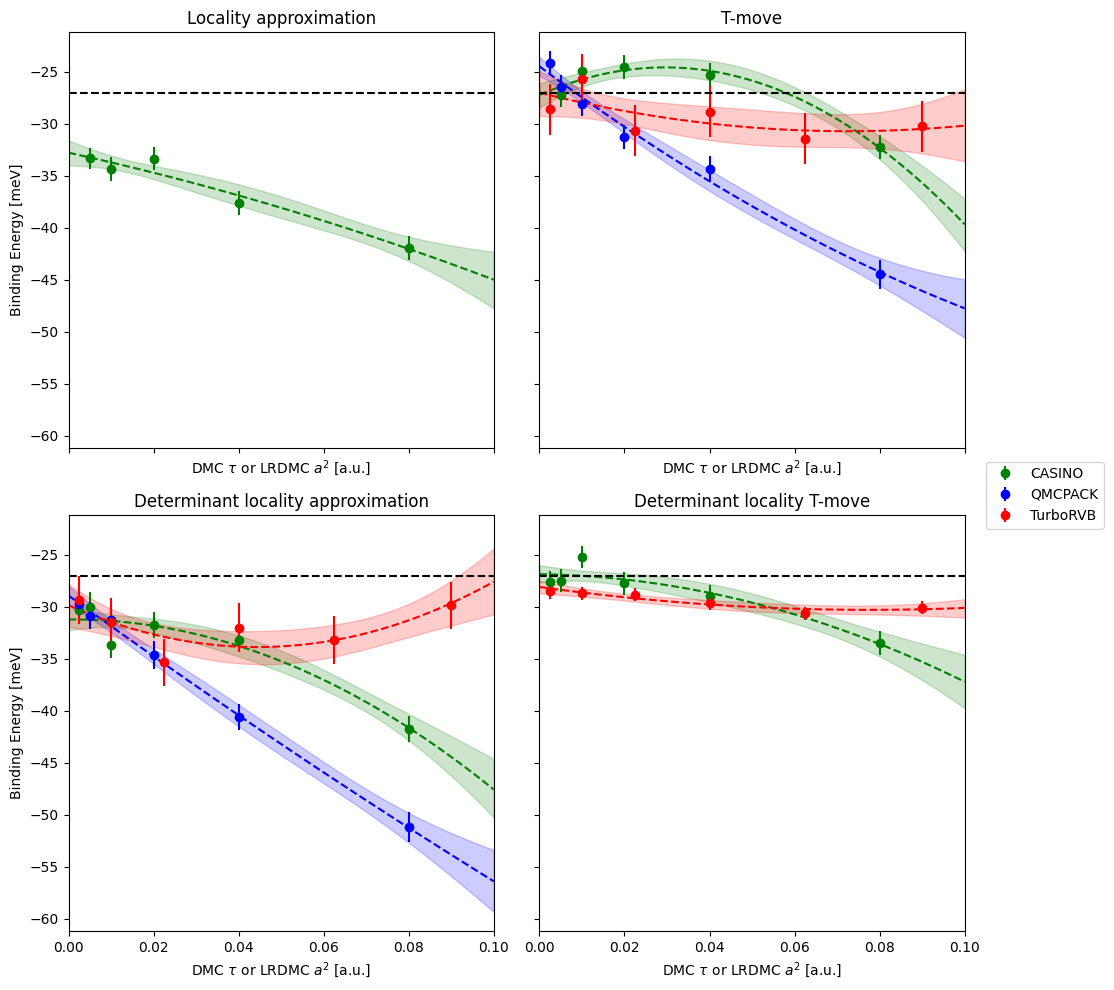

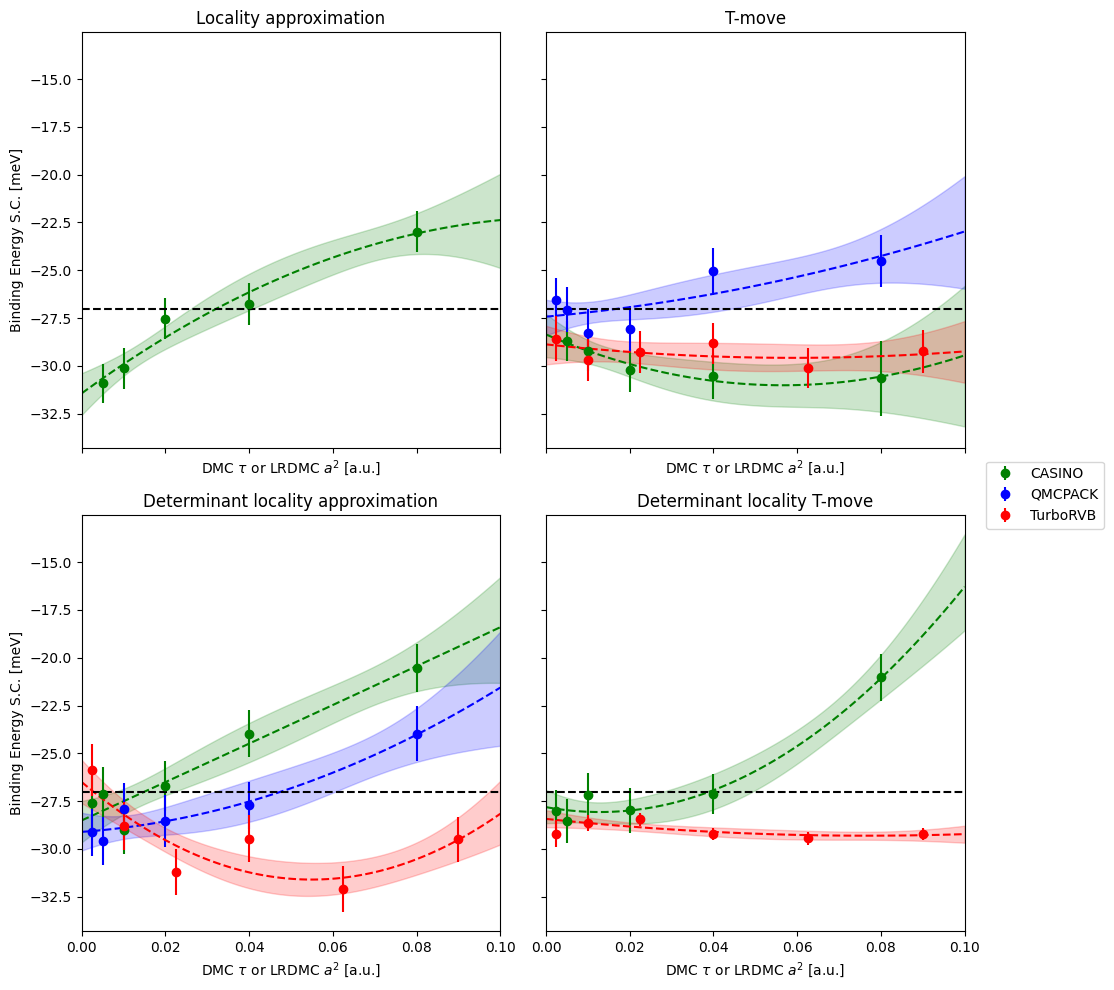

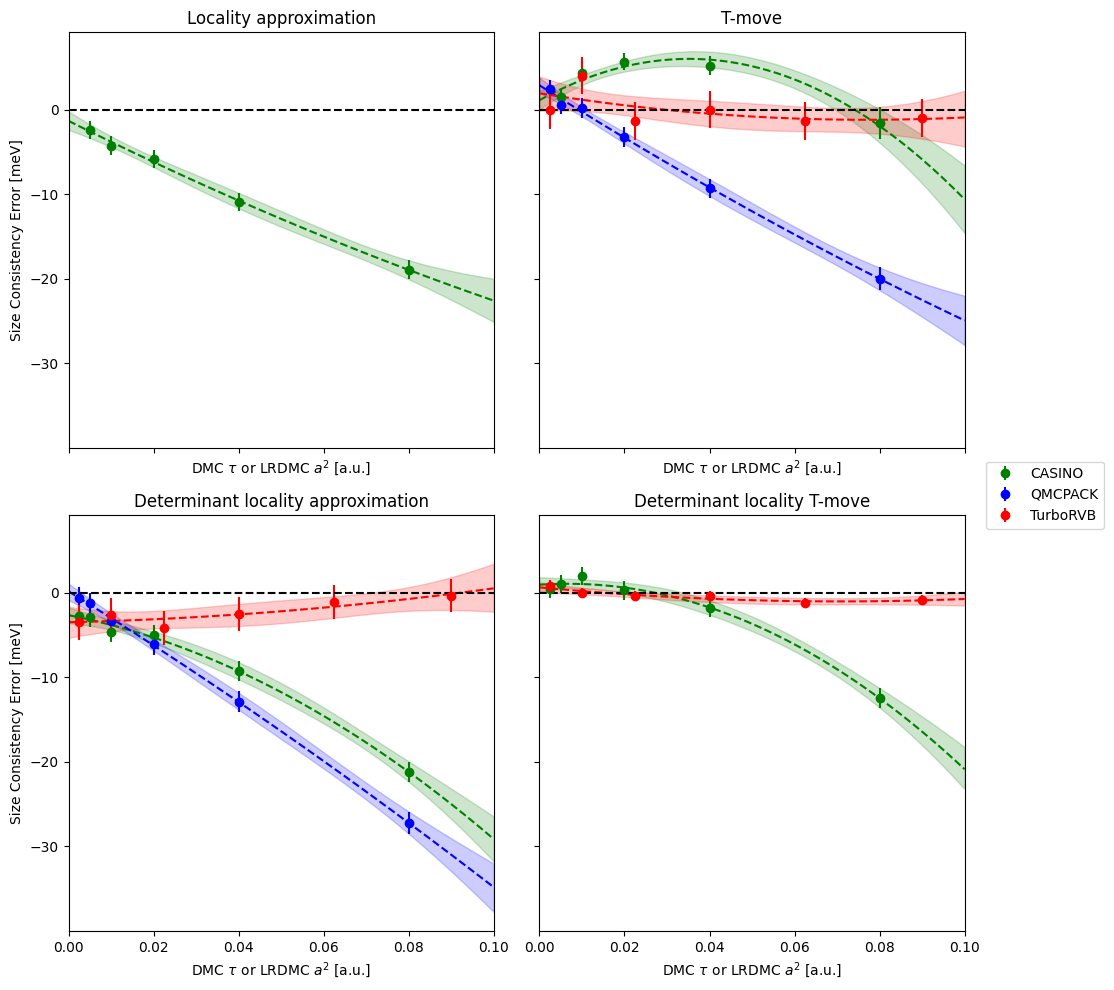

In [22]:
makefit = True
makefiterr = True
makefiterrOLS = False
verbose = False

# list with results
l = []

#for ed in ['Eb']:
for ed in Ediffs:
    fig, ax = plt.subplots(2,2, figsize=(10,10), sharey=True, sharex=True )
    ax[0][0].set_ylabel( Ediffs_label[ed] )
    ax[1][0].set_ylabel( Ediffs_label[ed] )

    for i, method in enumerate(methods):
        axi = ax[int(i/2)][i%2]
        if i==0:
            axi.set_title('Locality approximation')
        elif i==1:
            axi.set_title('T-move')
        elif i==2:
            axi.set_title('Determinant locality approximation')
        elif i==3:
            axi.set_title('Determinant locality T-move')

        axi.set_xlim(0,taumax)
        axi.set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
        #for code in ['CASINO']:    # <=== selection
        for code in codes_sel:    # <=== selection
        #for code in codes_sel3:    # <=== selection
            #print(code)
            try:
                #print(data[code][f'SCE_{method}'])
                datac1 = data[code][f'{ed}_{method}']
                datac1['x'] = x_axis( datac1, code )
                datac = datac1[ datac1.x <= taumax ]
                datac = datac.dropna()
                x = datac.x
                y = datac.ene
                y_err = datac.err
                axi.errorbar( x, y, y_err, fmt='o', 
                               label=code, color=colors_all[code] )
                if makefit:
                    #print('Fit')
                    fun = fun_quad
                    xdata = x.to_numpy()
                    ydata = y.to_numpy()
                    sigma = y_err.to_numpy()
                    popt, pcov = curve_fit( fun, xdata=xdata, ydata=ydata, sigma=sigma )
                    chi2, ndof, alpha = get_chi2_alpha_fitfun( xdata, ydata, sigma, fun, popt )
                    xlinspace = np.linspace( 0, taumax, 100)
                    funlinspace = fun( xlinspace, *popt )
                    axi.plot( xlinspace, funlinspace, '--', color=colors_all[code] )
                    popterr = np.array([pcov[i,i] for i in range(len(pcov))])**0.5
                    if verbose:
                        print('FIT',code, method, ed)
                        print( f'popt = {popt}' )
                        print( f'perr = {popterr}' )
                        print( f'pcov = {pcov}' )
                        print( f'Eb = {popt[0]:6.2f} +/- {popterr[0]:4.2f}')
                        print( f'    chi2={chi2:5.3f}, df={ndof}, alpha={alpha:5.3f}' )
                    if makefiterrOLS:
                        if verbose:
                            print('FITERR OLS',code, method, ed)
                        # Y = a + b X + c X^2 + d X^3
                        # Var(Y) = Var(a) + Var(b) * X^2 + 2 * Cov(a,b) * X + ...
                        def fun_var_y( x, cov ):
                            s = 0.0
                            for i in range(len(cov)):
                                for j in range(len(cov)):
                                    s += cov[i,j] * x**(i+j) 
                            return s
                        popt, pcov = curve_fit( fun, xdata=xdata, ydata=ydata, sigma=sigma )
                        var_y = fun_var_y( xlinspace, pcov )
                        err_y = var_y**0.5
                        axi.plot(xlinspace,funlinspace+err_y,':',color=colors_all[code])
                        axi.plot(xlinspace,funlinspace-err_y,'-.',color=colors_all[code])
                    if makefiterr:
                        if verbose:
                            print('FITERR',code, method, ed)
                        xfit, m, s = fit_err(xdata,ydata,sigma,fitfun=fun,xmax=taumax)
                        #print('FITERR2',m,s)
                        #ax[i].plot(xfit,m,'--',color='k')
                        axi.fill_between(xfit,m-1*s,m+1*s,color=colors_all[code],alpha=0.2)
                        chi2, ndof, alpha = get_chi2_alpha_parfun( xdata, ydata, sigma, xfit, m, p=1 )
                        if verbose:
                            print(f'Eb = {m[0]:6.2f} +/- {s[0]:4.2f} <=== fiterror')
                            print( f'    chi2={chi2:5.3f}, df={ndof}, alpha={alpha:5.3f}' )
                            print()
                        # save results
                        res = {}
                        res['Q'] = ed
                        res['method'] = method
                        res['code'] = code
                        res['ene'] = popt[0]
                        res['err'] = s[0]
                        res['err_fit'] = popterr[0]
                        res['chi2'] = chi2
                        res['ndof'] = ndof
                        res['alpha'] = alpha
                        l.append(res)

            except Exception as e:
                print('EXCEPTION > ',code, method, ed, e,'\n')
                #print(xdata)
                pass
        axi.axhline(y=Ediffs_ref[ed],color='black',ls='--')


    leg = {}
    for i in range(2): 
        for j in range(2): 
            handles, labels = ax[i][j].get_legend_handles_labels()
            for j in range(len(labels)):
                leg[labels[j]] = handles[j]
        import collections
        leg = collections.OrderedDict(sorted(leg.items()))
    #aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
    legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


    plt.tight_layout()
    fig.savefig(f'Fig22_{ed}_fit.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')
    
# df results
#print(l)
dfr = pd.DataFrame(l)
print(dfr)
dfr.to_csv(f'results_DE.csv')
dfDE = dfr

EXCEPTION >  QMCPACK LA m 'NoneType' object has no attribute 'index' 

EXCEPTION >  TurboRVB LA m 'NoneType' object has no attribute 'index' 



/Users/zen/.pyenv/versions/3.10.9/lib/python3.10/site-packages/scipy/optimize/_minpack_py.py:881: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


EXCEPTION >  QMCPACK DLTM m 'NoneType' object has no attribute 'index' 

EXCEPTION >  QMCPACK LA w 'NoneType' object has no attribute 'index' 

EXCEPTION >  TurboRVB LA w 'NoneType' object has no attribute 'index' 

EXCEPTION >  QMCPACK DLTM w 'NoneType' object has no attribute 'index' 

EXCEPTION >  QMCPACK LA mw 'NoneType' object has no attribute 'index' 

EXCEPTION >  TurboRVB LA mw 'NoneType' object has no attribute 'index' 

EXCEPTION >  QMCPACK DLTM mw 'NoneType' object has no attribute 'index' 

EXCEPTION >  QMCPACK LA m---w 'NoneType' object has no attribute 'index' 

EXCEPTION >  TurboRVB LA m---w 'NoneType' object has no attribute 'index' 

EXCEPTION >  QMCPACK DLTM m---w 'NoneType' object has no attribute 'index' 

     syst method      code        ene       err   err_fit       chi2  ndof  \
0       m     LA    CASINO  -8.081941  0.000020  0.000009   0.449430     3   
1       m     TM    CASINO  -8.081013  0.000013  0.000020   5.866958     4   
2       m     TM   QMCPACK  -8

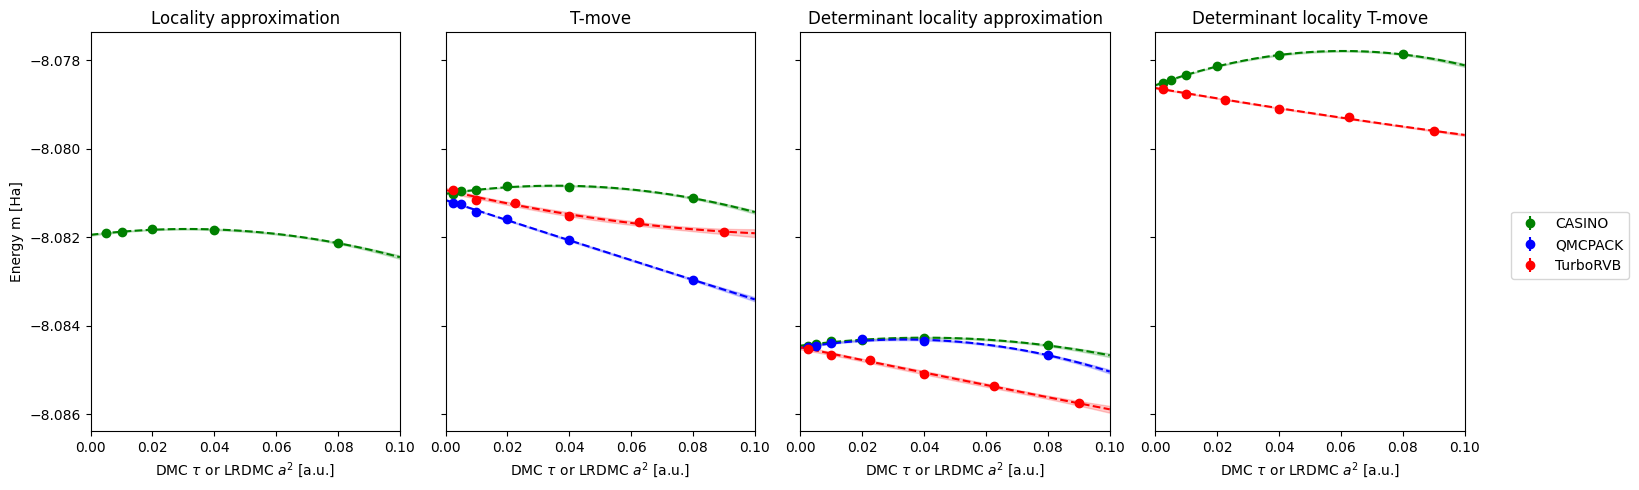

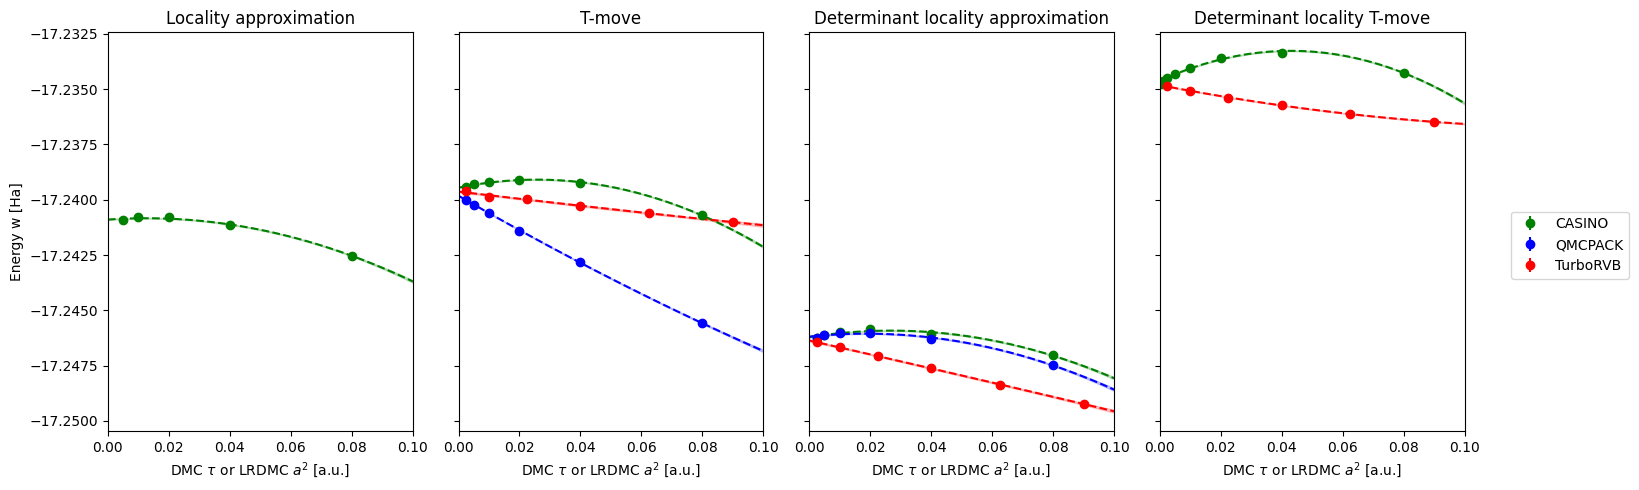

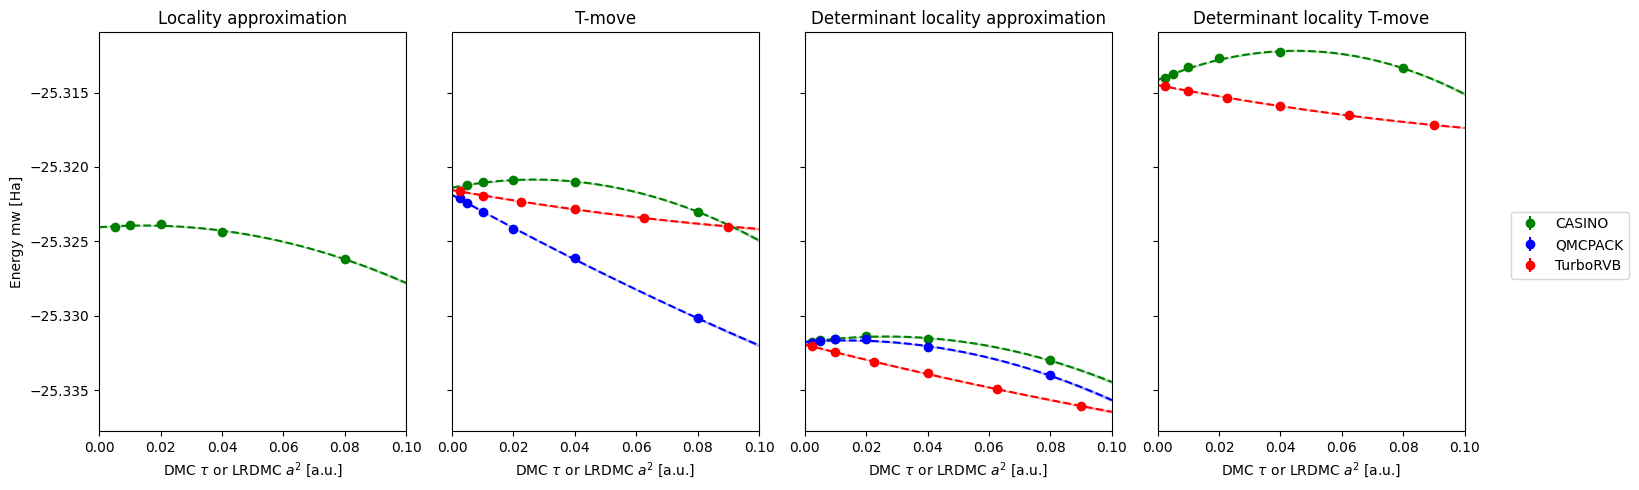

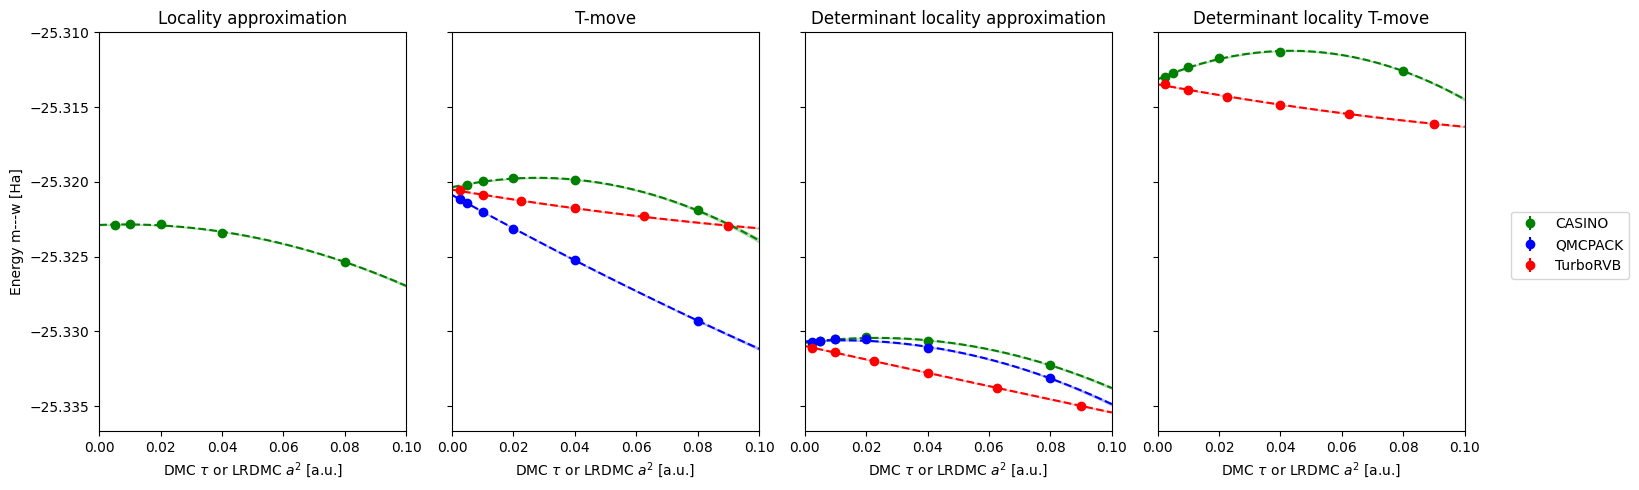

In [8]:
makefit = True
makefiterr = True
makefiterrOLS = False
verbose = False

# list with results
l = []

for syst in systems:
    fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )
    ax[0].set_ylabel( f'Energy {syst} [Ha]' )

    for i, method in enumerate(methods):
        ax[i].set_xlim(0,taumax)
        ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
        #for code in ['CASINO']:    # <=== selection
        for code in codes_sel:    # <=== selection
        #for code in codes_sel3:    # <=== selection
            #print(code)
            try:
                #print(data[code][f'SCE_{method}'])
                datac1 = data[code][f'{syst}_{method}']
                datac1['x'] = x_axis( datac1, code )
                datac = datac1[ datac1.x <= taumax ]
                datac = datac.dropna()
                x = datac.x
                y = datac.ene
                y_err = datac.err
                ax[i].errorbar( x, y, y_err, fmt='o', 
                               label=code, color=colors_all[code] )
                if makefit:
                    #print('Fit')
                    fun = fun_quad
                    xdata = x.to_numpy()
                    ydata = y.to_numpy()
                    sigma = y_err.to_numpy()
                    popt, pcov = curve_fit( fun, xdata=xdata, ydata=ydata, sigma=sigma )
                    chi2, ndof, alpha = get_chi2_alpha_fitfun( xdata, ydata, sigma, fun, popt )
                    xlinspace = np.linspace( 0, taumax, 100)
                    funlinspace = fun( xlinspace, *popt )
                    ax[i].plot( xlinspace, funlinspace, '--', color=colors_all[code] )
                    popterr = np.array([pcov[i,i] for i in range(len(pcov))])**0.5
                    if verbose:
                        print('FIT',code, method, syst)
                        print( f'popt = {popt}' )
                        print( f'perr = {popterr}' )
                        print( f'pcov = {pcov}' )
                        print( f'Eb = {popt[0]:6.2f} +/- {popterr[0]:4.2f}')
                        print( f'    chi2={chi2:5.3f}, df={ndof}, alpha={alpha:5.3f}' )
                    if makefiterrOLS:
                        if verbose:
                            print('FITERR OLS',code, method, syst)
                        # Y = a + b X + c X^2 + d X^3
                        # Var(Y) = Var(a) + Var(b) * X^2 + 2 * Cov(a,b) * X + ...
                        def fun_var_y( x, cov ):
                            s = 0.0
                            for i in range(len(cov)):
                                for j in range(len(cov)):
                                    s += cov[i,j] * x**(i+j) 
                            return s
                        popt, pcov = curve_fit( fun, xdata=xdata, ydata=ydata, sigma=sigma )
                        var_y = fun_var_y( xlinspace, pcov )
                        err_y = var_y**0.5
                        ax[i].plot(xlinspace,funlinspace+err_y,':',color=colors_all[code])
                        ax[i].plot(xlinspace,funlinspace-err_y,'-.',color=colors_all[code])
                    if makefiterr:
                        if verbose:
                            print('FITERR',code, method, syst)
                        xfit, m, s = fit_err(xdata,ydata,sigma,fitfun=fun,xmax=taumax)
                        #print('FITERR2',m,s)
                        #ax[i].plot(xfit,m,'--',color='k')
                        ax[i].fill_between(xfit,m-1*s,m+1*s,color=colors_all[code],alpha=0.2)
                        chi2, ndof, alpha = get_chi2_alpha_parfun( xdata, ydata, sigma, xfit, m, p=1 )
                        if verbose:
                            print(f'Eb = {m[0]:6.2f} +/- {s[0]:4.2f} <=== fiterror')
                            print( f'    chi2={chi2:5.3f}, df={ndof}, alpha={alpha:5.3f}' )
                            print()
                        # save results
                        res = {}
                        res['syst'] = syst
                        res['method'] = method
                        res['code'] = code
                        res['ene'] = popt[0]
                        res['err'] = s[0]
                        res['err_fit'] = popterr[0]
                        res['chi2'] = chi2
                        res['ndof'] = ndof
                        res['alpha'] = alpha
                        l.append(res)

            except Exception as e:
                print('EXCEPTION > ',code, method, syst, e,'\n')
                #print(xdata)
                pass
        #ax[i].axhline(y=0,color='black',ls='--')

    ax[0].set_title('Locality approximation')
    ax[1].set_title('T-move')
    ax[2].set_title('Determinant locality approximation')
    ax[3].set_title('Determinant locality T-move')

    leg = {}
    for i in range(4): 
        handles, labels = ax[i].get_legend_handles_labels()
        for j in range(len(labels)):
            leg[labels[j]] = handles[j]
    import collections
    leg = collections.OrderedDict(sorted(leg.items()))
    #aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
    legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


    plt.tight_layout()
    fig.savefig(f'Fig_{syst}_fit.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')
    
# df results
#print(l)
dfr = pd.DataFrame(l)
print(dfr)
dfr.to_csv(f'results_Etot.csv')
dfET = dfr

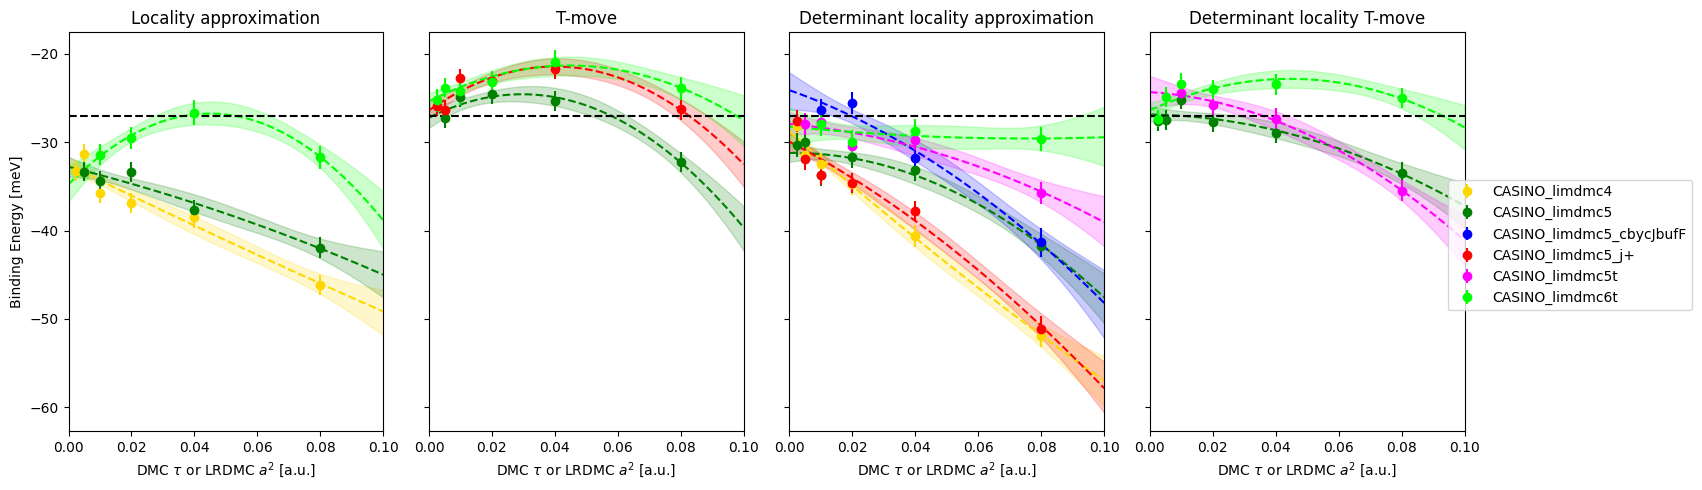

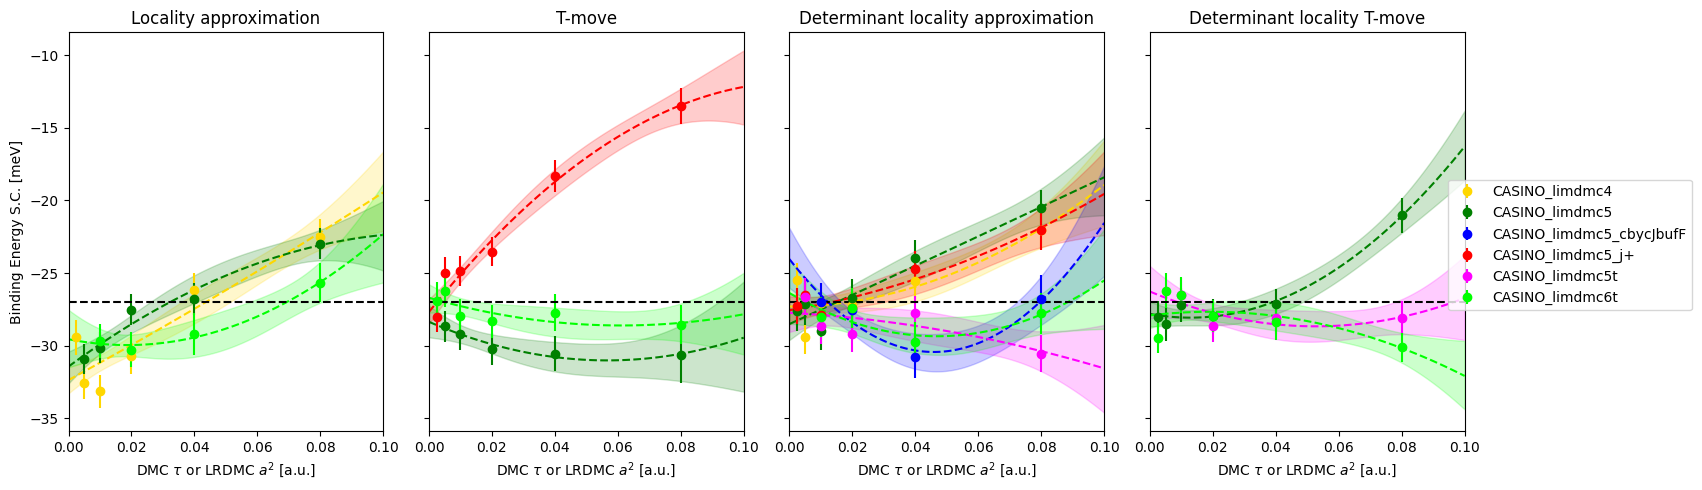

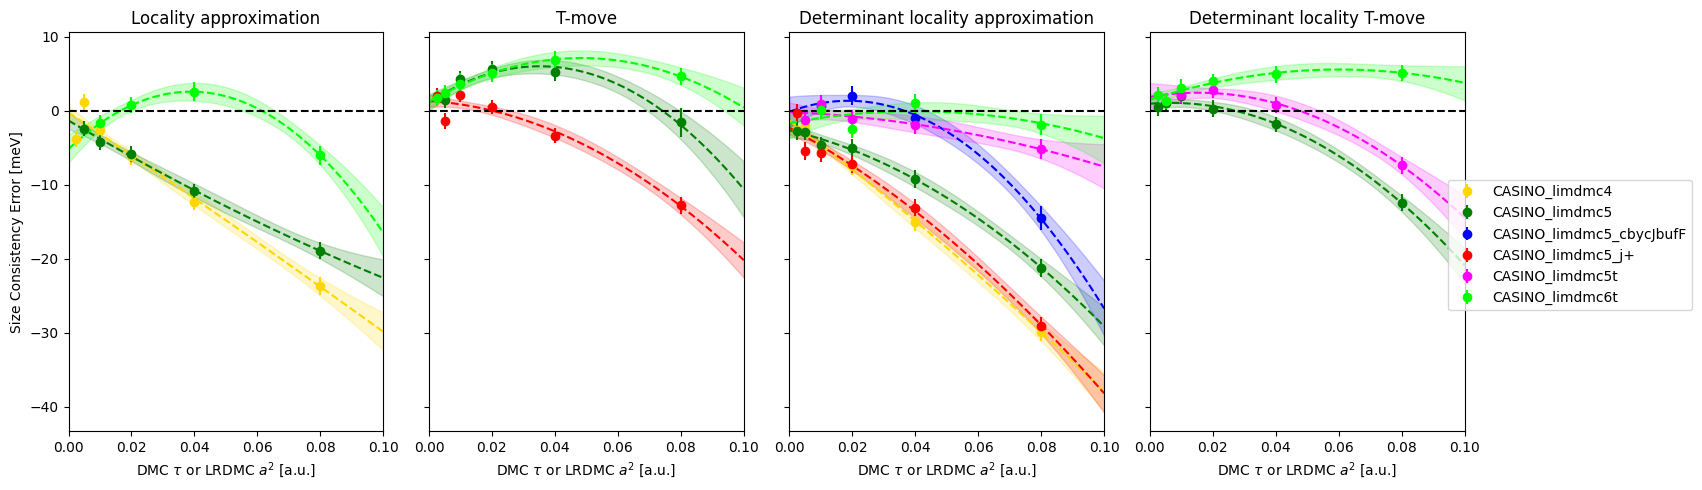

In [9]:
makefit = True
makefiterr = True
makefiterrOLS = False
verbose = False

#for ed in ['Eb']:
for ed in Ediffs:
    fig, ax = plt.subplots(1,4, figsize=(15,5), sharey=True, sharex=True )
    ax[0].set_ylabel( Ediffs_label[ed] )

    for i, method in enumerate(methods):
        ax[i].set_xlim(0,taumax)
        ax[i].set_xlabel( r'DMC $\tau$ or LRDMC $a^2$ [a.u.]' )
        for code in codes_casino:    # <=== selection
            #print(code)
            try:
                #print(data[code][f'SCE_{method}'])
                datac1 = data[code][f'{ed}_{method}']
                datac1['x'] = x_axis( datac1, code )
                datac = datac1[ datac1.x <= taumax ]
                datac = datac.dropna()
                x = datac.x
                y = datac.ene
                y_err = datac.err
                ax[i].errorbar( x, y, y_err, fmt='o', 
                               label=code, color=colors_all[code] )
                if makefit:
                    #print('Fit with quadratic function')
                    fun = fun_quad # lin quad cub
                    xdata = x.to_numpy()
                    ydata = y.to_numpy()
                    sigma = y_err.to_numpy()
                    popt, pcov = curve_fit( fun, xdata=xdata, ydata=ydata, sigma=sigma )
                    chi2, ndof, alpha = get_chi2_alpha_fitfun( xdata, ydata, sigma, fun, popt )
                    xlinspace = np.linspace( 0, taumax, 100)
                    funlinspace = fun( xlinspace, *popt )
                    ax[i].plot( xlinspace, funlinspace, '--', color=colors_all[code] )
                    popterr = np.array([pcov[i,i] for i in range(len(pcov))])**0.5
                    if verbose:
                        print('FIT',code, method, ed)
                        print( f'popt = {popt}' )
                        print( f'perr = {popterr}' )
                        print( f'pcov = {pcov}' )
                        print( f'Eb = {popt[0]:6.2f} +/- {popterr[0]:4.2f}')
                        print( f'    chi2={chi2:5.3f}, df={ndof}, alpha={alpha:5.3f}' )
                    if makefiterrOLS:
                        if verbose:
                            print('FITERR OLS',code, method, ed)
                        # Y = a + b X + c X^2 + d X^3
                        # Var(Y) = Var(a) + Var(b) * X^2 + 2 * Cov(a,b) * X + ...
                        def fun_var_y( x, cov ):
                            s = 0.0
                            for i in range(len(cov)):
                                for j in range(len(cov)):
                                    s += cov[i,j] * x**(i+j) 
                            return s
                        popt, pcov = curve_fit( fun, xdata=xdata, ydata=ydata, sigma=sigma )
                        var_y = fun_var_y( xlinspace, pcov )
                        err_y = var_y**0.5
                        ax[i].plot(xlinspace,funlinspace+err_y,':',color=colors_all[code])
                        ax[i].plot(xlinspace,funlinspace-err_y,'-.',color=colors_all[code])
                    if makefiterr:
                        if verbose:
                            print('FITERR',code, method, ed)
                        xfit, m, s = fit_err(xdata,ydata,sigma,fitfun=fun,xmax=taumax)
                        #print('FITERR2',m,s)
                        #ax[i].plot(xfit,m,'--',color='k')
                        ax[i].fill_between(xfit,m-1*s,m+1*s,color=colors_all[code],alpha=0.2)
                        chi2, ndof, alpha = get_chi2_alpha_parfun( xdata, ydata, sigma, xfit, m, p=1 )
                        if verbose:
                            print(f'Eb = {m[0]:6.2f} +/- {s[0]:4.2f} <=== fiterror')
                            print( f'    chi2={chi2:5.3f}, df={ndof}, alpha={alpha:5.3f}' )
                            print()

            except Exception as e:
                #print('EXCEPTION > ',code, method, ed, e,'\n')
                #print(xdata)
                pass
        ax[i].axhline(y=Ediffs_ref[ed],color='black',ls='--')

    ax[0].set_title('Locality approximation')
    ax[1].set_title('T-move')
    ax[2].set_title('Determinant locality approximation')
    ax[3].set_title('Determinant locality T-move')

    leg = {}
    for i in range(4): 
        handles, labels = ax[i].get_legend_handles_labels()
        for j in range(len(labels)):
            leg[labels[j]] = handles[j]
    import collections
    leg = collections.OrderedDict(sorted(leg.items()))
    #aus = leg['CCSD(T)']; del(leg['CCSD(T)']); leg['CCSD(T)']=aus
    legend_outside = fig.legend(labels=list(leg.keys()), handles=list(leg.values()), ncol=1, loc='center', bbox_to_anchor=( 1.05, 0.5))


    plt.tight_layout()
    fig.savefig(f'Fig_{ed}_fitcasino.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')

# Plot Extrapolated results

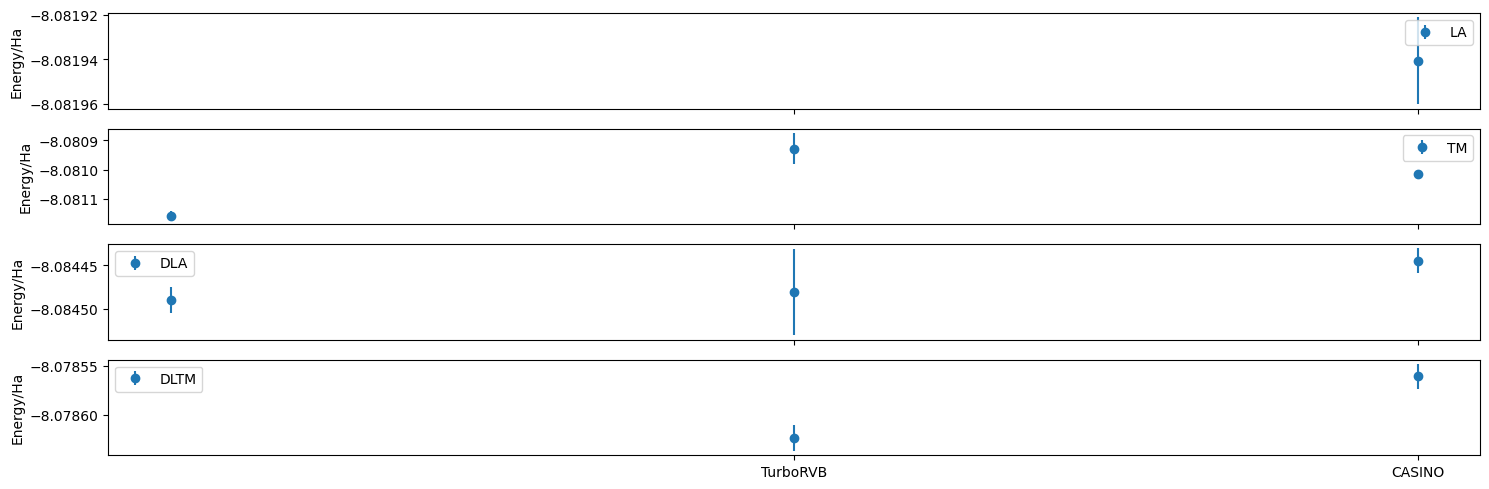

In [10]:
df = dfET
xlabels = set( df.code ) 
l = list( range(1,len(xlabels)+1) )
xval = dict(zip(xlabels,l))

import matplotlib
matplotlib.rcParams['axes.formatter.useoffset'] = False


#for s in systems:
for s in ['m']:
    fig, ax = plt.subplots(len(methods),1, figsize=(15,5), sharey=False, sharex=True )
    for i, m in enumerate(methods):
    #for m in ['DLA']:
        sel = (df.syst==s) & (df.method==m)
        x = df.loc[ sel ]
        ene = x.ene
        err = x.err
        xcode = list( x.code )
        xcodev = [ xval[xc] for xc in xcode ]
        #print(ene,err,xcode,xcodev)
        # fig
        ax[i].set_ylabel( 'Energy/Ha' )
        ax[i].errorbar( xcodev, ene, err, fmt='o', label=m)
        ax[i].legend()
    ax[i].set_xticks(xcodev,xcode)
    plt.tight_layout()
    fig.savefig(f'Fig_syst_{s}.png',bbox_extra_artists=(legend_outside,),bbox_inches='tight')


In [11]:
methods

['LA', 'TM', 'DLA', 'DLTM']

In [12]:
dfET.loc[ (dfET.syst=='m') & (dfET.code=='CASINO') ]

,syst,method,code,ene,err,err_fit,chi2,ndof,alpha
0,m,LA,CASINO,-8.081941,0.000020,0.000009,0.449430,3,0.929852
1,m,TM,CASINO,-8.081013,0.000013,0.000020,5.866958,4,0.209307
4,m,DLA,CASINO,-8.084445,0.000014,0.000017,3.938583,4,0.414381
7,m,DLTM,CASINO,-8.078561,0.000013,0.000009,1.135549,4,0.888592


In [13]:
sel = (dfET.syst=='m') & (dfET.method=='DLA') & (dfET.code=='CASINO') 
float(dfET[ sel ].ene)

-8.08444493561843